# Week 1 exercise: a simulated magnetic-field record

**Task (from the pre-lab plan):** synthesize a field record with 60 Hz and 180 Hz tones plus white and 1/f noise. Compute the FFT and a Welch power spectral density with correct units (G²/Hz). Check that the integrated PSD matches the time-domain variance.

**How to use this notebook**
- Run cells top to bottom with **Shift+Enter**.
- Wherever you see `# TODO`, replace the `...` with your own code. Hints are there if you get stuck.
- Each step ends with a **check** cell. Run it after your step. It prints ✅ when you got it right.
- Every number here is **simulated**, and the plots say so (lab-manual rule).

**Words you need**
- **Framerate (fs):** samples per second.
- **N:** total number of samples = fs × duration.
- **Gauss (G):** unit of magnetic field. 1 mG (milligauss) = 0.001 G.
- **σ (sigma), standard deviation:** the typical size of random wiggles.
- **Variance:** σ², the average of (value − mean)². This is the signal's total power.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

rng = np.random.default_rng(0)   # random-number generator; the 0 makes your results repeatable

## Step 1: time axis

Use a framerate of **10,000 samples per second** for **10 seconds**.

- `fs` = framerate, `T` = duration in seconds, `N` = number of samples.
- `t` = the time of every sample: 0, 1/fs, 2/fs, … up to (but not including) T.

*Why 10,000/s?* The Nyquist frequency is fs/2 = 5,000 Hz, far above the 180 Hz we care about, so there's no aliasing (chapter 2).
*Why 10 s?* Frequency resolution = 1/T = 0.1 Hz (chapter 7).

In [10]:
# TODO
fs = 10_000
T = 10
N = fs * T
t = np.arange(N) / fs     # array of N sample times, in seconds

<details><summary><b>Hint (click if stuck)</b></summary>

`N = fs * T`, and `t = np.arange(N) / fs`. `np.arange(N)` gives 0, 1, 2, …, N−1, and dividing by fs turns sample numbers into seconds.

</details>

In [11]:
# check
assert N == 100_000 and len(t) == N and abs(t[1] - 1e-4) < 1e-12, "check fs, T, N and t"
print("✅ step 1")

✅ step 1


## Step 2: the two line tones

Make the line-synchronous part of the field (chapter 1: `amplitude × cos(2π × frequency × t)`):
- 60 Hz with amplitude **0.30 mG**;
- 180 Hz (3rd harmonic) with amplitude **0.10 mG** and a phase of **0.5 radians** (it starts at a different point in its cycle).

**Work in gauss**, so 0.30 mG is written `0.30e-3`.

In [14]:
# TODO
a60  = 0.30e-3     # G  (SIMULATED)
a180 = 0.10e-3     # G  (SIMULATED)
tones = a60 * np.cos(2*np.pi*60*t) + a180 * np.cos(2*np.pi*180*t + 0.5)       # a60 * cos(...) + a180 * cos(... + 0.5)

<details><summary><b>Hint (click if stuck)</b></summary>

`tones = a60*np.cos(2*np.pi*60*t) + a180*np.cos(2*np.pi*180*t + 0.5)`

</details>

In [15]:
# check
assert tones.shape == (N,) and abs(tones.max() - (a60 + a180)) < 0.05e-3, "check your cosines (units in gauss?)"
print("✅ step 2")

✅ step 2


## Step 3: white noise

White noise (chapter 4) = every sample independent and random. Draw N values from a normal (bell-curve) distribution with mean 0 and **σ = 0.05 mG**.

In [18]:
# TODO
sigma_white = 0.05e-3   # G (SIMULATED)
white = rng.normal(0, sigma_white, N)             # use rng.normal(mean, sigma, how_many)

<details><summary><b>Hint (click if stuck)</b></summary>

`white = rng.normal(0, sigma_white, N)`

</details>

In [19]:
# check
assert white.shape == (N,) and abs(white.std() - sigma_white) < 0.002e-3
print("✅ step 3")

✅ step 3


## Step 4: 1/f (pink) noise

Pink noise has **power ∝ 1/f** (chapter 4). Power is amplitude squared, so the **amplitude** of each frequency goes like **1/√f**.

Recipe (this is the same idea ThinkDSP's `PinkNoise` uses):
1. Make white noise with σ = 1 and take its `rfft` (go to the frequency domain).
2. Get the matching frequencies with `np.fft.rfftfreq(N, 1/fs)`.
3. Divide every value except the first (f = 0, you can't divide by 0) by √f. Set the f = 0 value to 0.
4. `irfft` back to the time domain.
5. Rescale so its standard deviation is **0.05 mG**.

In [23]:
# TODO
X = np.fft.rfft(rng.normal(0, 1, N))                       # 1. rfft of white noise with sigma 1
freqs = np.fft.rfftfreq(N, 1/fs)                   # 2. matching frequencies
X[1:] = X[1:]/np.sqrt(freqs[1:])                   # 3. divide by sqrt(f)
X[0] = 0
pink = np.fft.irfft(X, n=N)                    # 4. back to time: np.fft.irfft(X, n=N)
pink *= 0.05e-3/pink.std()                    # 5. rescale to std 0.05e-3

<details><summary><b>Hint (click if stuck)</b></summary>

```python
X = np.fft.rfft(rng.normal(0, 1, N))
freqs = np.fft.rfftfreq(N, 1/fs)
X[1:] = X[1:] / np.sqrt(freqs[1:])
X[0] = 0
pink = np.fft.irfft(X, n=N)
pink = pink * (0.05e-3 / pink.std())
```

</details>

In [24]:
# check
assert pink.shape == (N,) and abs(pink.std() - 0.05e-3) < 1e-9, "rescale step"
fp, Pp = signal.welch(pink, fs=fs, nperseg=fs)
slope = np.polyfit(np.log10(fp[1:1000]), np.log10(Pp[1:1000]), 1)[0]
print(f"log-log slope of your pink noise: {slope:.2f}  (should be close to -1)")
assert -1.3 < slope < -0.7
print("✅ step 4")

log-log slope of your pink noise: -0.99  (should be close to -1)
✅ step 4


## Step 5: the full record, plotted

Add the three parts: `B = tones + white + pink`. Then plot the **first 100 ms** in milligauss (multiply by 1000 for display only). Label the axes and put **SIMULATED** in the title.

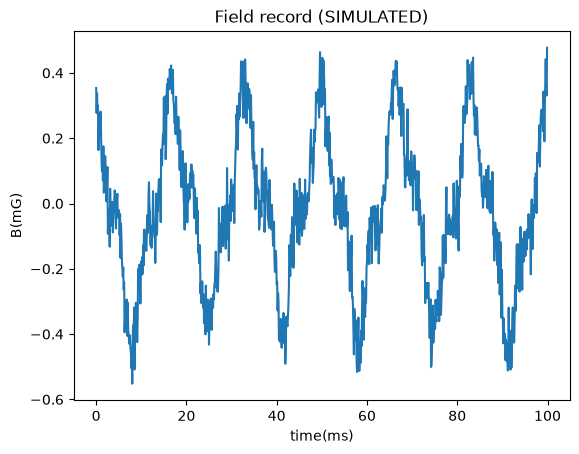

In [25]:
# TODO
B = tones + white + pink

# plot the first 100 ms (how many samples is that?)
plt.plot(t[:1000]*1e3, B[:1000]*1e3) # 1e3 is a unit change from seconds to ms, 1 s = 1000 ms
plt.xlabel("time(ms)"); plt.ylabel("B(mG)"); plt.title("Field record (SIMULATED)")
plt.show()

<details><summary><b>Hint (click if stuck)</b></summary>

100 ms = 0.1 s = 0.1 × fs = 1000 samples.
```python
B = tones + white + pink
plt.plot(t[:1000]*1e3, B[:1000]*1e3)
plt.xlabel("time (ms)"); plt.ylabel("B (mG)"); plt.title("Field record (SIMULATED)")
plt.show()
```

</details>

In [26]:
# check
assert np.allclose(B, tones + white + pink)
print("✅ step 5")

✅ step 5


## Step 6: FFT and tone amplitudes

Chapter 7: `np.fft.rfft` gives one complex number per frequency. To get a tone's **amplitude**, use **2·|X|/N**.

1. Compute `X_B` and `f`.
2. Compute `amp = 2*np.abs(X_B)/N` (gauss).
3. Plot amp (in mG) vs f, from 0 to 300 Hz.
4. Print the amplitude at 60 Hz and 180 Hz. *Which bin is 60 Hz?* Bin spacing is 1/T = 0.1 Hz, so 60 Hz is bin 600. Or find it with `np.argmin(np.abs(f - 60))`.

60 Hz: 0.299 mG   180 Hz: 0.100 mG   (SIMULATED)


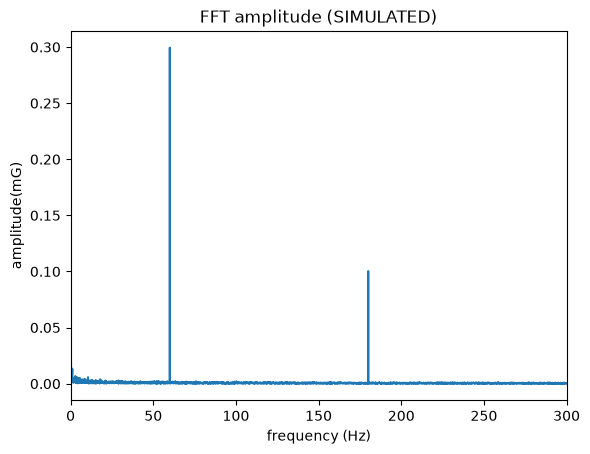

In [27]:
# TODO
X_B = np.fft.rfft(B)
f = np.fft.rfftfreq(N, 1/fs)
amp = 2*np.abs(X_B)/N

i60 = np.argmin(np.abs(f - 60))
i180 = np.argmin(np.abs(f - 180))
print(f"60 Hz: {amp[i60]*1e3:.3f} mG   180 Hz: {amp[i180]*1e3:.3f} mG   (SIMULATED)")

# plot
plt.plot(f, amp*1e3); plt.xlim(0, 300)
plt.xlabel("frequency (Hz)"); plt.ylabel("amplitude(mG)"); plt.title("FFT amplitude (SIMULATED)");
plt.show()

<details><summary><b>Hint (click if stuck)</b></summary>

```python
X_B = np.fft.rfft(B); f = np.fft.rfftfreq(N, 1/fs); amp = 2*np.abs(X_B)/N
i60 = np.argmin(np.abs(f - 60)); i180 = np.argmin(np.abs(f - 180))
plt.plot(f, amp*1e3); plt.xlim(0, 300)
plt.xlabel("frequency (Hz)"); plt.ylabel("amplitude (mG)"); plt.title("FFT amplitude (SIMULATED)"); plt.show()
```

</details>

In [ ]:
# check: you put in 0.30 and 0.10 mG; the FFT should give them back
assert abs(amp[i60] - a60) < 0.01e-3 and abs(amp[i180] - a180) < 0.01e-3, "amplitudes off: check the 2/N scaling"
print("✅ step 6")

## Step 7: Welch PSD in G²/Hz

The **PSD** (power spectral density) tells you how much power (signal²) is in each 1 Hz slice. Since B is in gauss, its PSD is in **G²/Hz**.

Welch's method cuts the record into pieces, windows each one (stops leakage, chapter 3), and averages their spectra. Use `nperseg=fs` (1-second pieces → 1 Hz resolution, 10 pieces averaged).

Plot it on **log-log axes** (`plt.loglog`). You should see:
- spikes at 60 and 180 Hz (the tones);
- a downward slope at low f (the 1/f noise);
- a flat floor at high f (the white noise).

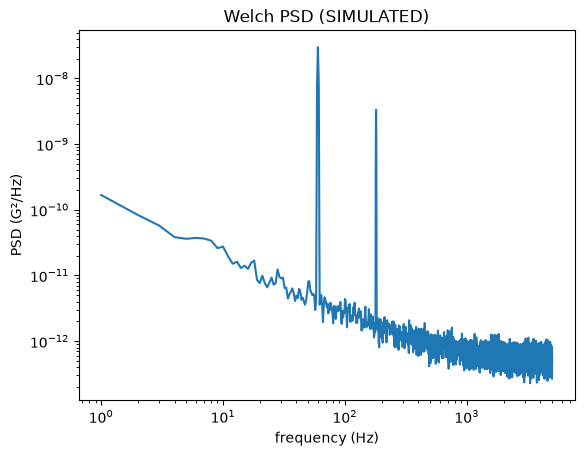

In [29]:
# TODO
fw, P = signal.welch(B, fs=fs, nperseg=fs)    # scipy.signal.welch(...)

# loglog plot with labelled axes, units G²/Hz, SIMULATED in title
plt.loglog(fw[1:],P[1:])
plt.xlabel("frequency (Hz)"); plt.ylabel("PSD (G²/Hz)"); plt.title("Welch PSD (SIMULATED)"); plt.show()


<details><summary><b>Hint (click if stuck)</b></summary>

```python
fw, P = signal.welch(B, fs=fs, nperseg=fs)
plt.loglog(fw[1:], P[1:])          # skip f = 0, log(0) is undefined
plt.xlabel("frequency (Hz)"); plt.ylabel("PSD (G²/Hz)"); plt.title("Welch PSD (SIMULATED)"); plt.show()
```

</details>

In [30]:
# check: the white-noise floor should be sigma²/(fs/2) G²/Hz (white noise spreads its power evenly from 0 to Nyquist)
floor = np.median(P[(fw > 2000) & (fw < 4500)])
print(f"high-f floor: {floor:.2e} G²/Hz, expected about {(0.05e-3)**2/(fs/2):.2e}")
assert 0.7 < floor / ((0.05e-3)**2/(fs/2)) < 1.4
print("✅ step 7")

high-f floor: 5.61e-13 G²/Hz, expected about 5.00e-13
✅ step 7


## Step 8: does the area under the PSD equal the variance?

**Parseval's theorem:** total power is the same whether you measure it in time or in frequency.
- Time domain: `np.var(B)` (G²).
- Frequency domain: the area under the PSD = sum of P × bin width Δf (G²/Hz × Hz = G²).

Also predict it **by hand**: a cosine of amplitude a has power a²/2; noise has power σ². Fill in `predicted`.

In [ ]:
# TODO
var_time = np.var(B)
df = fw[1] - fw[0]                 # bin width of fw, in Hz
var_freq = np.sum(P)*df           # area under P
predicted = a60**2/2 + a180**2/2 + sigma_white**2 + (0.05e-3)**2          # by hand, in G²

print(f"time: {var_time:.3e} G²   PSD area: {var_freq:.3e} G²   by hand: {predicted:.3e} G²")
print(f"difference: {abs(var_time - var_freq)/var_time*100:.1f}%")

<details><summary><b>Hint (click if stuck)</b></summary>

```python
var_time = np.var(B)
df = fw[1] - fw[0]
var_freq = np.sum(P) * df
predicted = a60**2/2 + a180**2/2 + sigma_white**2 + (0.05e-3)**2
```
By hand: 0.30²/2 + 0.10²/2 + 0.05² + 0.05² = 0.045 + 0.005 + 0.0025 + 0.0025 = 0.055 mG² = 5.5e-8 G².

</details>

In [ ]:
# check
assert abs(var_time - var_freq) / var_time < 0.03, "PSD area and variance should agree within a few %"
assert abs(predicted - 5.5e-8) < 1e-10
print("✅ step 8: Parseval checks out. Units are right.")

## Self-check questions (answer in your lab notebook, in your own words)

1. Why does 60 Hz land exactly in bin 600 of the FFT? What would change with 10.05 s of data? (Hint: leakage.)
2. Why is the tone amplitude 2·|X|/N and not |X|/N?
3. What are the units of the PSD, and why does multiplying by Δf give the variance?
4. On the log-log PSD, how can you tell which noise is white and which is 1/f?
5. If you used `nperseg=fs//10` instead, what happens to the frequency resolution and the noisiness of the PSD? Try it.
6. Connect it to the project: if this were a real measurement, which numbers tell you how much the line wobble needs to be cancelled?

**Experiments to try:** double the white-noise σ and predict the new variance before running; add a 300 Hz tone; change `T` to 10.05 and look at the 60 Hz peak.